# 03 – RootSIFT and OpponentSIFT

This notebook reuses the keypoints from Stage 2. RootSIFT is calculated from cached SIFT descriptors; OpponentSIFT is extracted at the same keypoint locations in three opponent-colour channels.

# Project setup

This notebook uses the shared functions in `visual_search/`. The dataset and generated feature caches stay outside GitHub.
If your Google Drive folder is different, edit `PROJECT_ROOT` and `DATASET_SOURCE` below.

In [ ]:
from pathlib import Path
import sys

# Mount Google Drive when this notebook is running in Colab.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_ROOT = Path("/content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3")
DATASET_SOURCE = Path("/content/drive/MyDrive/cvpr_coursework/MSRC_ObjCategImageDatabase_v2")

if not (PROJECT_ROOT / "cvpr").is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing cvpr/ and visual_search/.")
if not (PROJECT_ROOT / "visual_search").is_dir():
    raise FileNotFoundError("The visual_search package is missing from PROJECT_ROOT.")

sys.path.insert(0, str(PROJECT_ROOT))
print("Project:", PROJECT_ROOT)

Mounted at /content/drive
Project: /content/drive/MyDrive/cvpr_coursework/EEE3032_Coursework_Starter_v3


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from cvpr.dataset import load_split_records, read_rgb
from cvpr.baseline import global_rgb_histogram
from cvpr.retrieval import compute_descriptors
from cvpr.evaluation import evaluate_retrieval, per_category_summary
from cvpr.plotting import show_ranked_results

from visual_search.features import create_sift
from visual_search.cache import feature_cache_path, load_feature_cache

MANIFEST = PROJECT_ROOT / "split_manifest.csv"
gallery, dev, test = load_split_records(
    DATASET_SOURCE,
    manifest_path=MANIFEST,
    extract_dir=PROJECT_ROOT / "data",
)
assert (len(gallery), len(dev), len(test)) == (391, 100, 100)
print(f"Loaded {len(gallery)} gallery, {len(dev)} development and {len(test)} test images.")

Loaded 391 gallery, 100 development and 100 test images.


In [ ]:
import cv2
from visual_search.features import root_sift, opponent_channels, extract_opponent_sift, create_sift
from visual_search.cache import (
    feature_cache_path, load_feature_cache, cache_opponent_features, validate_cache_set
)

detected_cache = PROJECT_ROOT / "sift_cache" / "detected_sift"
dense_cache = PROJECT_ROOT / "sift_cache" / "dense_sift_step12_size16"
detected_opponent_cache = PROJECT_ROOT / "sift_cache" / "stage3_opponent_sift" / "detected"
dense_opponent_cache = PROJECT_ROOT / "sift_cache" / "stage3_opponent_sift" / "dense"

## 1. Check RootSIFT on a small example

RootSIFT keeps the descriptor dimension unchanged. It L1-normalises each row and takes its element-wise square root.

In [ ]:
example = np.array([[4, 2, 2, 0]], dtype=np.float32)
transformed = root_sift(example)
print("Input:", example)
print("RootSIFT:", np.round(transformed, 3))
print("Output shape:", transformed.shape)
print("L2 norm:", np.linalg.norm(transformed, axis=1))
assert transformed.shape == example.shape
assert np.allclose(np.linalg.norm(transformed, axis=1), 1.0)

Input: [[4. 2. 2. 0.]]
RootSIFT: [[0.707 0.5   0.5   0.   ]]
Output shape: (1, 4)
L2 norm: [1.]


## 2. Inspect the opponent-colour channels

The channel ranges are fixed across all images. O1 and O2 are signed colour-opponent responses mapped into uint8 for OpenCV; O3 represents intensity.

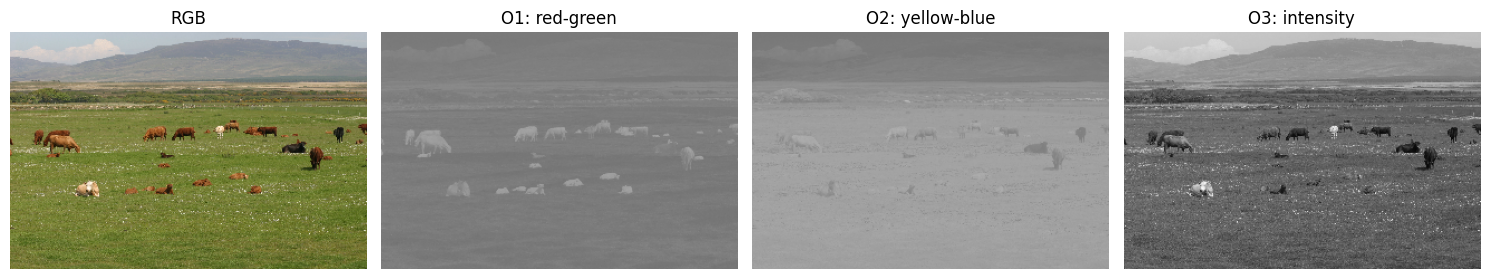

In [ ]:
sample = read_rgb(gallery[0].path)
channels = opponent_channels(sample)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(sample); axes[0].set_title("RGB")
for axis, channel, label in zip(axes[1:], channels, ["O1: red-green", "O2: yellow-blue", "O3: intensity"]):
    axis.imshow(channel, cmap="gray", vmin=0, vmax=255)
    axis.set_title(label)
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()

## 3. Extract OpponentSIFT for the gallery

 reuse the keypoint positions from the detected and dense SIFT caches. The three channel descriptors are concatenated, producing 384 values per location.

In [ ]:
detected_counts = cache_opponent_features(
    gallery, detected_cache, detected_opponent_cache, rebuild=False
)
dense_counts = cache_opponent_features(
    gallery, dense_cache, dense_opponent_cache, rebuild=False
)

detected_check = validate_cache_set(gallery, detected_opponent_cache, 384)
dense_check = validate_cache_set(gallery, dense_opponent_cache, 384)
print("Detected OpponentSIFT:", detected_check)
print("Dense OpponentSIFT:", dense_check)

Processed 50/391 images
Processed 100/391 images
Processed 150/391 images
Processed 200/391 images
Processed 250/391 images
Processed 300/391 images
Processed 350/391 images
Processed 391/391 images
Processed 50/391 images
Processed 100/391 images
Processed 150/391 images
Processed 200/391 images
Processed 250/391 images
Processed 300/391 images
Processed 350/391 images
Processed 391/391 images
Detected OpponentSIFT: {'images': 391, 'descriptor_dimension': 384, 'minimum_descriptors': 3, 'mean_descriptors': 464.02813299232736, 'maximum_descriptors': 1331}
Dense OpponentSIFT: {'images': 391, 'descriptor_dimension': 384, 'minimum_descriptors': 442, 'mean_descriptors': 450.9104859335038, 'maximum_descriptors': 494}


## 4. Verify all four descriptor variants

Root descriptors are transformations of the cached raw descriptors, so they do not need separate cache files.

In [ ]:
sample_record = gallery[0]
sample_index = 0
variants = [
    ("detected SIFT", detected_cache, 128, False),
    ("detected RootSIFT", detected_cache, 128, True),
    ("detected OpponentSIFT", detected_opponent_cache, 384, False),
    ("detected RootOpponentSIFT", detected_opponent_cache, 384, True),
    ("dense SIFT", dense_cache, 128, False),
    ("dense RootSIFT", dense_cache, 128, True),
    ("dense OpponentSIFT", dense_opponent_cache, 384, False),
    ("dense RootOpponentSIFT", dense_opponent_cache, 384, True),
]

for name, folder, dimension, apply_root in variants:
    values = load_feature_cache(
        feature_cache_path(folder, sample_index, sample_record),
        sample_record.filename, dimension,
    )
    if apply_root:
        values = root_sift(values)
    print(f"{name:28s} {values.shape}")
    assert np.isfinite(values).all()

detected SIFT                (164, 128)
detected RootSIFT            (164, 128)
detected OpponentSIFT        (164, 384)
detected RootOpponentSIFT    (164, 384)
dense SIFT                   (442, 128)
dense RootSIFT               (442, 128)
dense OpponentSIFT           (442, 384)
dense RootOpponentSIFT       (442, 384)
